# Project 01: Which bank clients should the call team phone first?
## Exploratory data analysis (EDA)

**Business question.** A bank's phone team cannot call everyone. Before they pick up the phone, which clients should they call first?

**Data.** Bank Marketing (`bank-additional-full.csv`): 41,188 phone calls made by a Portuguese bank, each with the outcome `y` (did the client subscribe to a term deposit: yes or no).
Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306 (licence: CC BY 4.0).

**How this notebook is organised.** Each section has a *Purpose* (why we do the step), the *code*, and a *Conclusion* (what the result tells us and how it changes our plan).

**AI use.** This notebook was built with an AI assistant. How it was used is recorded in `prompt_chat_history.md`.

**The one rule used throughout.** A column may be used to predict only if it is known *at the moment the prediction is made*. For this project, that moment is **before the phone call**.

## 1. Load the data from SQLite

**Purpose.** Confirm that we can read back exactly what `src/get_data.py` stored, and that the rows are still in their original order (`row_id`). The order matters later: the file is ordered by date.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The notebook may be run from the project folder or from the repository root.
candidates = [Path("data/bank.db"), Path("projects/01-bank-call-targeting/data/bank.db")]
DB_PATH = next(p for p in candidates if p.exists())

conn = sqlite3.connect(DB_PATH)
df = pd.read_sql("SELECT * FROM bank_marketing ORDER BY row_id", conn)
conn.close()

print(f"database file: {DB_PATH.name}")
print(f"rows: {len(df):,}   columns: {df.shape[1]}")
df.head()

database file: bank.db
rows: 41,188   columns: 22


,row_id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,0,56,housemaid,married,basic.4y,no,no,no,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,1,57,services,married,high.school,unknown,no,no,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,2,37,services,married,high.school,no,yes,no,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,3,40,admin.,married,basic.6y,no,no,no,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,4,56,services,married,high.school,no,no,yes,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


**Conclusion.** We have 41,188 rows and 22 columns: the 21 original columns plus `row_id`, which we added to preserve the file's order. Loading with `ORDER BY row_id` guarantees we see the rows in that order.

## 2. Class balance and the blind-guess baselines

**Purpose.** Before judging any model, know what a model with no skill would score. Two baselines:
- **Accuracy of "always say no"**: the share of "no" clients.
- **PR-AUC of a random guesser**: the share of "yes" clients (the positive rate).

A model is only impressive if it beats these *on the same data it is scored on*.

yes: 4,640   no: 36,548
positive rate (random-guess PR-AUC): 0.1127  (11.3%)
accuracy of 'always say no':          0.8873  (88.7%)


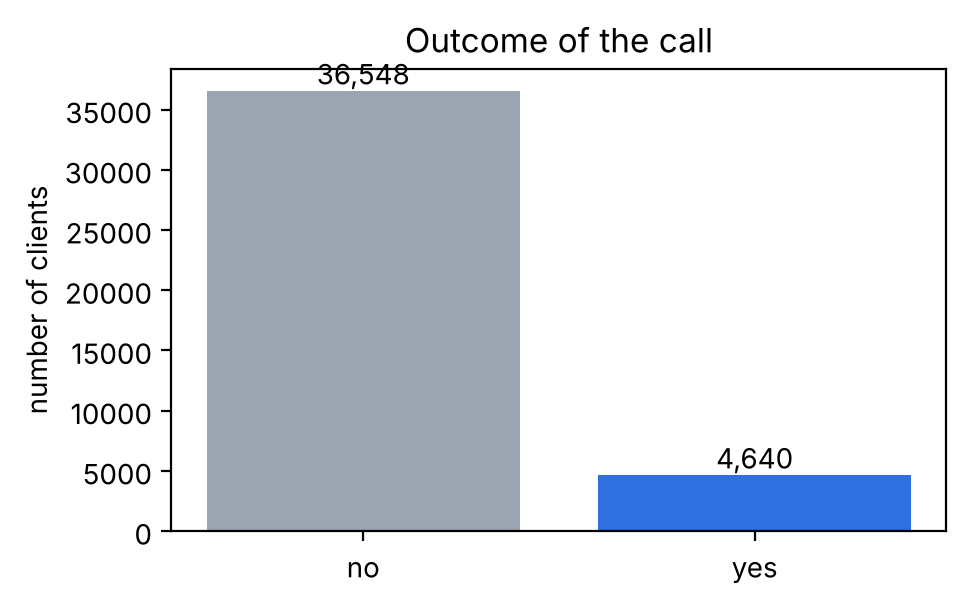

In [2]:
n_rows = len(df)
n_yes = int((df["y"] == "yes").sum())
n_no = n_rows - n_yes

positive_rate = n_yes / n_rows
always_no_accuracy = n_no / n_rows

print(f"yes: {n_yes:,}   no: {n_no:,}")
print(f"positive rate (random-guess PR-AUC): {positive_rate:.4f}  ({positive_rate:.1%})")
print(f"accuracy of 'always say no':          {always_no_accuracy:.4f}  ({always_no_accuracy:.1%})")

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(["no", "yes"], [n_no, n_yes], color=["#9aa5b1", "#2f6fdf"])
ax.set_ylabel("number of clients")
ax.set_title("Outcome of the call")
for i, v in enumerate([n_no, n_yes]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.show()

**Conclusion.** Only 11.3% of calls end in a "yes". The data is imbalanced, so:
- A model that always says "no" is right 88.7% of the time. **Accuracy is therefore a poor yardstick here**: a high accuracy would not show any skill.
- A random guesser has PR-AUC of about 0.113. Any real model must clearly beat that.
- This 11.3% is for the whole file. Section 3 shows that the share of "yes" changes a lot over time, which means every set we score on has its own baseline.

## 3. The row order is a clock

**Purpose.** The file has no date column, only `month` and `day_of_week`. The dataset's authors state the rows are ordered by date (May 2008 to November 2010). Our split into training and test data depends on that order, so we check it before relying on it.

**Method.** Walk down the rows and cut a new "block" each time the month name changes. If the data is in date order, the blocks should follow the calendar, and a month name should return only after a full year.

In [3]:
MONTH_NUMBER = {m: i for i, m in enumerate(
    ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], start=1)}

block_id = (df["month"] != df["month"].shift()).cumsum()
blocks = df.groupby(block_id).agg(
    month=("month", "first"),
    first_row=("row_id", "min"),
    rows=("row_id", "size"),
).reset_index(drop=True)
blocks.index = blocks.index + 1
blocks.index.name = "block"

# The year is NOT in the data. We infer it: the year goes up each time the calendar wraps around.
month_no = blocks["month"].map(MONTH_NUMBER)
blocks["inferred_year"] = 2008 + (month_no < month_no.shift()).cumsum()

print(f"number of blocks: {len(blocks)}")
blocks

number of blocks: 26


,month,first_row,rows,inferred_year
block,,,,
1,may,0,7763,2008
2,jun,7763,4374,2008
3,jul,12137,6685,2008
4,aug,18822,5175,2008
5,oct,23997,67,2008
6,nov,24064,3616,2008
7,dec,27680,10,2008
8,mar,27690,282,2009
9,apr,27972,2458,2009


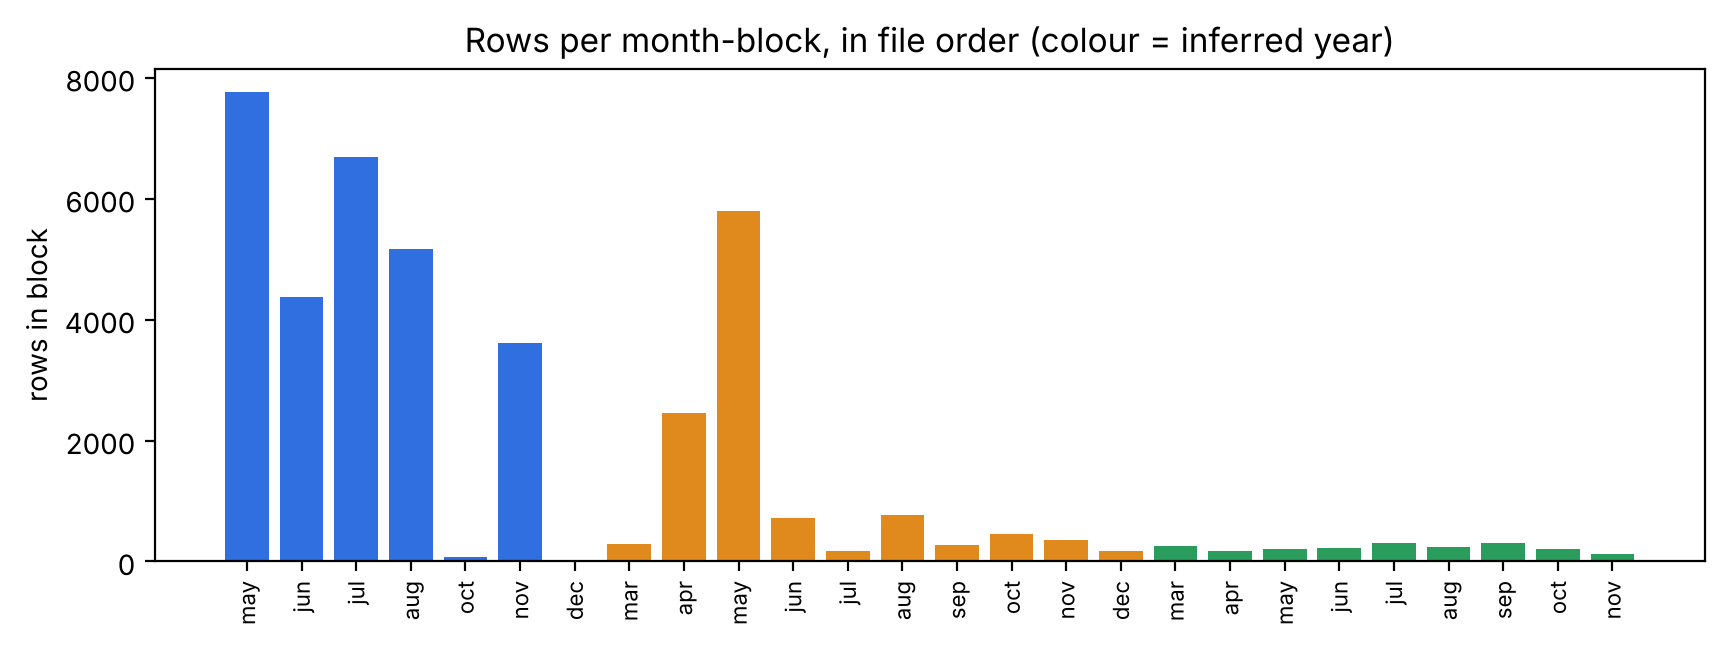

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.2))
colors = {2008: "#2f6fdf", 2009: "#e08a1e", 2010: "#2a9d5c"}
ax.bar(blocks.index, blocks["rows"], color=blocks["inferred_year"].map(colors))
ax.set_xticks(blocks.index)
ax.set_xticklabels(blocks["month"], rotation=90, fontsize=8)
ax.set_ylabel("rows in block")
ax.set_title("Rows per month-block, in file order (colour = inferred year)")
plt.show()

**Conclusion so far.** There are 26 blocks and they follow the calendar: May to Dec (skipping Sep), then Mar to Dec, then Mar to Nov. The month names wrap around exactly twice, which gives three years, and this matches the authors' May 2008 to Nov 2010 statement. So the **row order is a valid clock**, but the year is *inferred*, not recorded. Most rows come from the first year, and the later years are much smaller.

Next, what does that clock do to the outcome? We check how the share of "yes" changes by year, then where a 70% / 15% / 15% chronological split would fall.

In [5]:
df["inferred_year"] = block_id.map(blocks["inferred_year"])

by_year = df.groupby("inferred_year").agg(
    rows=("row_id", "size"),
    yes_rate=("y", lambda s: (s == "yes").mean()),
)
by_year["share_of_all_rows"] = by_year["rows"] / len(df)
print(by_year.assign(
    yes_rate=by_year["yes_rate"].map("{:.1%}".format),
    share_of_all_rows=by_year["share_of_all_rows"].map("{:.1%}".format)))

# Where would a chronological 70 / 15 / 15 split put its boundaries?
train_end = int(len(df) * 0.70)
valid_end = int(len(df) * 0.85)
segments = {"train": df.iloc[:train_end], "validation": df.iloc[train_end:valid_end], "test": df.iloc[valid_end:]}

rows = []
for name, part in segments.items():
    rows.append({
        "segment": name,
        "rows": len(part),
        "from": f"{part['month'].iloc[0]} {part['inferred_year'].iloc[0]}",
        "to": f"{part['month'].iloc[-1]} {part['inferred_year'].iloc[-1]}",
        "yes_rate (= random-guess PR-AUC)": f"{(part['y'] == 'yes').mean():.1%}",
    })
pd.DataFrame(rows).set_index("segment")

                rows yes_rate share_of_all_rows
inferred_year                                  
2008           27690     4.8%             67.2%
2009           11440    19.5%             27.8%
2010            2058    52.1%              5.0%


,rows,from,to,yes_rate (= random-guess PR-AUC)
segment,,,,
train,28831,may 2008,apr 2009,5.6%
validation,6178,apr 2009,may 2009,10.7%
test,6179,may 2009,nov 2010,38.5%


**Conclusion.**
- The share of "yes" grows sharply over time: **4.8% in 2008, 19.5% in 2009, 52.1% in 2010** (years are inferred).
- A 70 / 15 / 15 chronological split gives a training set (May 2008 to Apr 2009) with **5.6% yes**, a validation set (Apr to May 2009) with **10.7%**, and a test set (May 2009 to Nov 2010) with **38.5%**.
- So the blind-guess PR-AUC is about **0.056 on training, 0.107 on validation and 0.385 on test**. A PR-AUC of 0.40 would be strong on the training period and almost no better than guessing on the test set.
- Plan consequences: **always compare a score with the baseline of the same set**; never compare PR-AUC across sets; and expect the test period to behave differently from the training period. We will state this plainly when we report results.
- We don't know *why* the yes-rate rises (more targeted calling, the economy, a change in who was called?). That is a question for the bank.

## 4. Data quality

**Purpose.** Find the problems that would silently damage a model: missing values hidden as text, duplicates, special codes and impossible values.

In [6]:
categorical = df.drop(columns=["row_id"]).select_dtypes(exclude="number").columns
unknown_counts = {c: int((df[c] == "unknown").sum()) for c in categorical if (df[c] == "unknown").any()}
unknown_table = pd.DataFrame({"unknown_count": unknown_counts})
unknown_table["share_of_rows"] = (unknown_table["unknown_count"] / len(df)).map("{:.1%}".format)
display(unknown_table)

n_duplicates = int(df.drop(columns=["row_id", "inferred_year"]).duplicated().sum())
print(f"exact duplicate rows (ignoring row_id): {n_duplicates}")

,unknown_count,share_of_rows
job,330,0.8%
marital,80,0.2%
education,1731,4.2%
default,8597,20.9%
housing,990,2.4%
loan,990,2.4%


exact duplicate rows (ignoring row_id): 12


In [7]:
# pdays: days since the client was last contacted in an EARLIER campaign. 999 is a special code.
pdays_999 = df["pdays"] == 999
print(f"pdays == 999 in {pdays_999.mean():.1%} of rows")
print()
print("poutcome (outcome of the earlier campaign) against pdays == 999:")
display(pd.crosstab(pdays_999.rename("pdays == 999"), df["poutcome"]))

print()
print("numeric columns:")
display(df[["age", "duration", "campaign", "pdays", "previous"]].describe().T.round(1))
print(f"calls with duration == 0 seconds: {int((df['duration'] == 0).sum())}")

pdays == 999 in 96.3% of rows

poutcome (outcome of the earlier campaign) against pdays == 999:


poutcome,failure,nonexistent,success
pdays == 999,,,
False,142,0,1373
True,4110,35563,0



numeric columns:


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.0,10.4,17.0,32.0,38.0,47.0,98.0
duration,41188.0,258.3,259.3,0.0,102.0,180.0,319.0,4918.0
campaign,41188.0,2.6,2.8,1.0,1.0,2.0,3.0,56.0
pdays,41188.0,962.5,186.9,0.0,999.0,999.0,999.0,999.0
previous,41188.0,0.2,0.5,0.0,0.0,0.0,0.0,7.0


calls with duration == 0 seconds: 4


**Conclusion.**
- **Missing values hide as the text `unknown`.** The biggest is `default` (8,597 rows, about 21%), then `education` (1,731), `housing` and `loan` (990 each), `job` (330) and `marital` (80). Pandas does not count these as missing, so we must handle them on purpose. We will keep `unknown` as its own category, because "we don't know" may itself carry information.
- **12 exact duplicates** out of 41,188 rows (0.03%): too few to matter, but we will remove them in the pipeline and say so.
- **`pdays == 999` is a code, not a number.** It covers 96.3% of rows. Averaging it as a number would be wrong, so we will turn it into a yes/no flag ("contacted in an earlier campaign") plus the real day count where it exists.
- **One surprise.** Every row with a real `pdays` has a recorded outcome, as expected. But 4,110 rows with `pdays == 999` also show `poutcome == "failure"`, even though 999 is documented as "not previously contacted". So 999 is not a clean "never contacted". Why is unknown to us, and we should ask the bank. For now we treat the two columns as separate signals.
- **Odd values.** Four calls lasted 0 seconds (probably no real conversation; unverified). The longest call is 4,918 seconds. One client was contacted 56 times in a campaign. Ages run from 17 to 98. None of these are impossible, so we keep them and watch for their influence.

## 5. Column timing audit (the leakage rule)

**Purpose.** For each column: is it known *before the phone call*? A column known only during or after the call would let a model "peek at the answer". The audit table records one decision per column: **use**, **exclude** or **unsure**.

In [8]:
audit = pd.DataFrame([
    ("age, job, marital, education", "client profile", "before the call", "use", "Known from the bank's records."),
    ("default, housing, loan", "client's credit / loan status", "before the call", "use", "Known from records; many 'unknown'."),
    ("contact", "phone type used for this call", "when the call is planned", "use", "The channel is chosen before dialling."),
    ("month, day_of_week", "when the (last) contact took place", "unsure", "unsure", "May describe the very call we predict; month also acts as a clock."),
    ("duration", "length of the call in seconds", "AFTER the call", "exclude", "The authors say it is unknown before the call. Used only in a labelled demo."),
    ("campaign", "contacts in this campaign, including the last one", "unsure", "unsure", "'Including the last contact' may include the call being predicted."),
    ("pdays, previous, poutcome", "history from an earlier campaign", "before the call", "use", "Handle the 999 code."),
    ("emp_var_rate, cons_price_idx, cons_conf_idx, euribor3m, nr_employed", "economy at the time of the call", "public at the time", "unsure", "Known then, but may mostly tell us WHICH PERIOD a row is from (see section 6)."),
    ("y", "did the client subscribe?", "after the call", "target", "This is what we predict."),
], columns=["columns", "what it is", "when it is known", "decision", "reason"])
audit

,columns,what it is,when it is known,decision,reason
0,"age, job, marital, education",client profile,before the call,use,Known from the bank's records.
1,"default, housing, loan",client's credit / loan status,before the call,use,Known from records; many 'unknown'.
2,contact,phone type used for this call,when the call is planned,use,The channel is chosen before dialling.
3,"month, day_of_week",when the (last) contact took place,unsure,unsure,May describe the very call we predict; month a...
4,duration,length of the call in seconds,AFTER the call,exclude,The authors say it is unknown before the call....
5,campaign,"contacts in this campaign, including the last one",unsure,unsure,'Including the last contact' may include the c...
6,"pdays, previous, poutcome",history from an earlier campaign,before the call,use,Handle the 999 code.
7,"emp_var_rate, cons_price_idx, cons_conf_idx, e...",economy at the time of the call,public at the time,unsure,"Known then, but may mostly tell us WHICH PERIO..."
8,y,did the client subscribe?,after the call,target,This is what we predict.


**Conclusion.**
- **Exclude `duration`.** The call length is only known once the call is over, so a model that uses it is cheating. Section 6 shows how strong the effect is.
- **Three groups are marked "unsure"** because we cannot tell from the description alone: `month` / `day_of_week`, `campaign`, and the five economic indicators. We will not silently keep or drop them: we will run the model with and without each group and report the change in score (an *ablation*).
- **Questions to ask the bank:** (1) Does `campaign` count the call whose outcome we want to predict? (2) Is the month/day the date of that call or of an earlier one? (3) Why do some rows combine `pdays = 999` with a recorded earlier "failure"?

## 6. Outcome rate by column value

**Purpose.** Two jobs at once: (a) see which columns carry a real signal for "yes"; (b) catch suspicious columns, where the "yes" rate is near 0% or near 100%, or is wildly different between groups.

In [9]:
def yes_rate_by(column, data=df):
    table = data.groupby(column, observed=True)["y"].agg(
        clients="size", yes_rate=lambda s: (s == "yes").mean())
    return table.sort_values("yes_rate", ascending=False)

def show_rates(column):
    table = yes_rate_by(column)
    print(f"--- {column} ---")
    display(table.assign(yes_rate=table["yes_rate"].map("{:.1%}".format)))

for column in ["job", "contact", "poutcome"]:
    show_rates(column)

--- job ---


,clients,yes_rate
job,,
student,875,31.4%
retired,1720,25.2%
unemployed,1014,14.2%
admin.,10422,13.0%
management,2924,11.2%
unknown,330,11.2%
technician,6743,10.8%
self-employed,1421,10.5%
housemaid,1060,10.0%


--- contact ---


,clients,yes_rate
contact,,
cellular,26144,14.7%
telephone,15044,5.2%


--- poutcome ---


,clients,yes_rate
poutcome,,
success,1373,65.1%
failure,4252,14.2%
nonexistent,35563,8.8%


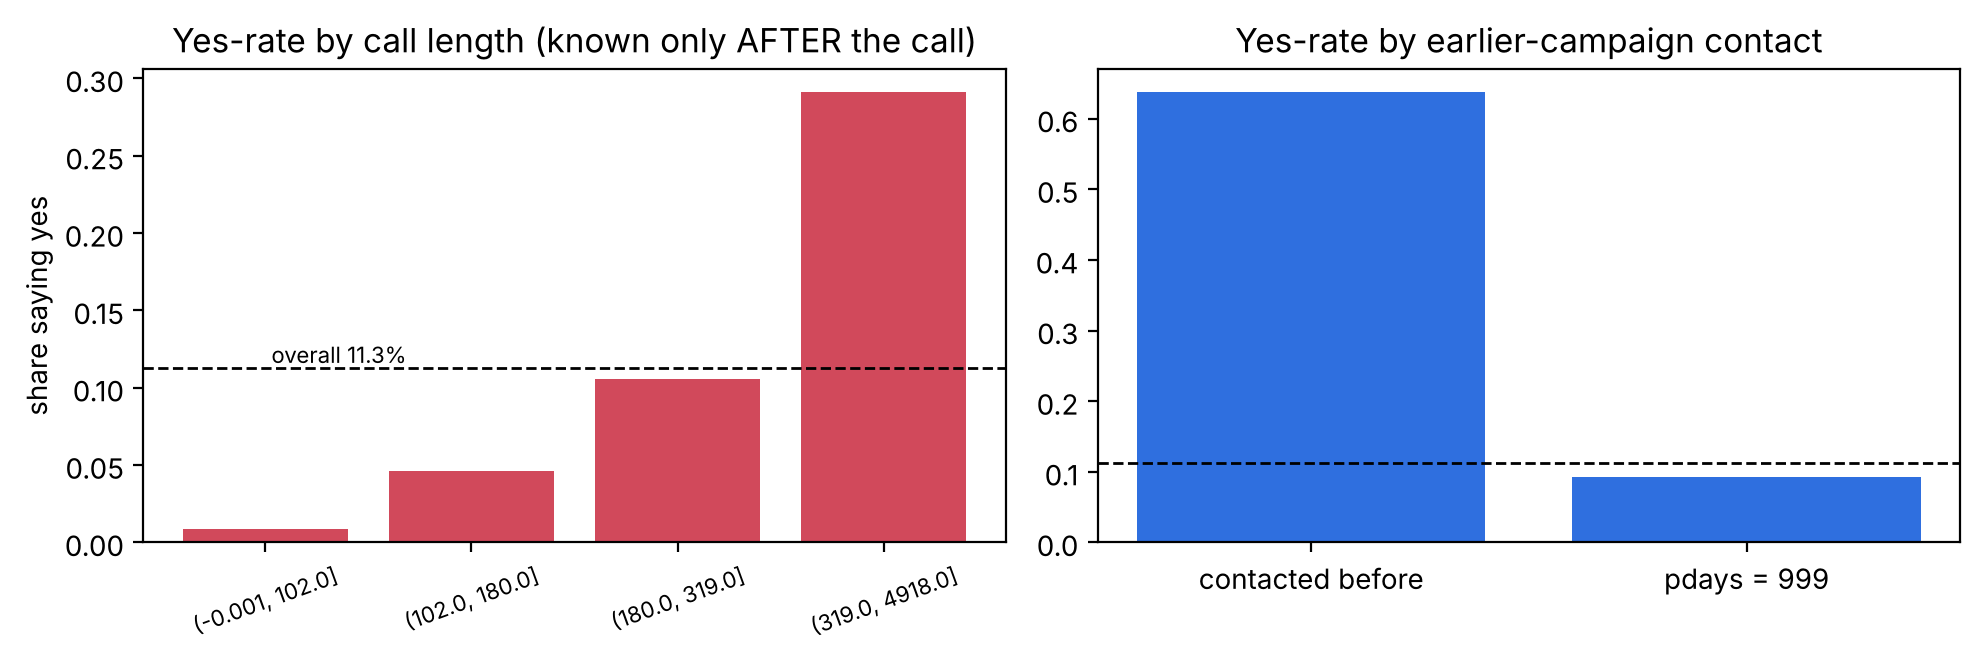

In [10]:
# Leakage demo: yes-rate by call length (duration), in four equal-sized groups.
duration_group = pd.qcut(df["duration"], 4)
by_duration = df.groupby(duration_group, observed=True)["y"].apply(lambda s: (s == "yes").mean())

# Earlier-campaign contact: pdays == 999 versus a real number of days.
by_pdays = df.groupby(np.where(df["pdays"] == 999, "pdays = 999", "contacted before"))["y"].apply(
    lambda s: (s == "yes").mean())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].bar([str(i) for i in by_duration.index], by_duration.values, color="#d1495b")
axes[0].set_title("Yes-rate by call length (known only AFTER the call)")
axes[0].set_ylabel("share saying yes")
axes[0].tick_params(axis="x", labelrotation=20, labelsize=8)
axes[0].axhline(positive_rate, color="black", linestyle="--", linewidth=1)
axes[0].text(0, positive_rate, " overall 11.3%", va="bottom", fontsize=8)

axes[1].bar(by_pdays.index, by_pdays.values, color="#2f6fdf")
axes[1].set_title("Yes-rate by earlier-campaign contact")
axes[1].axhline(positive_rate, color="black", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()

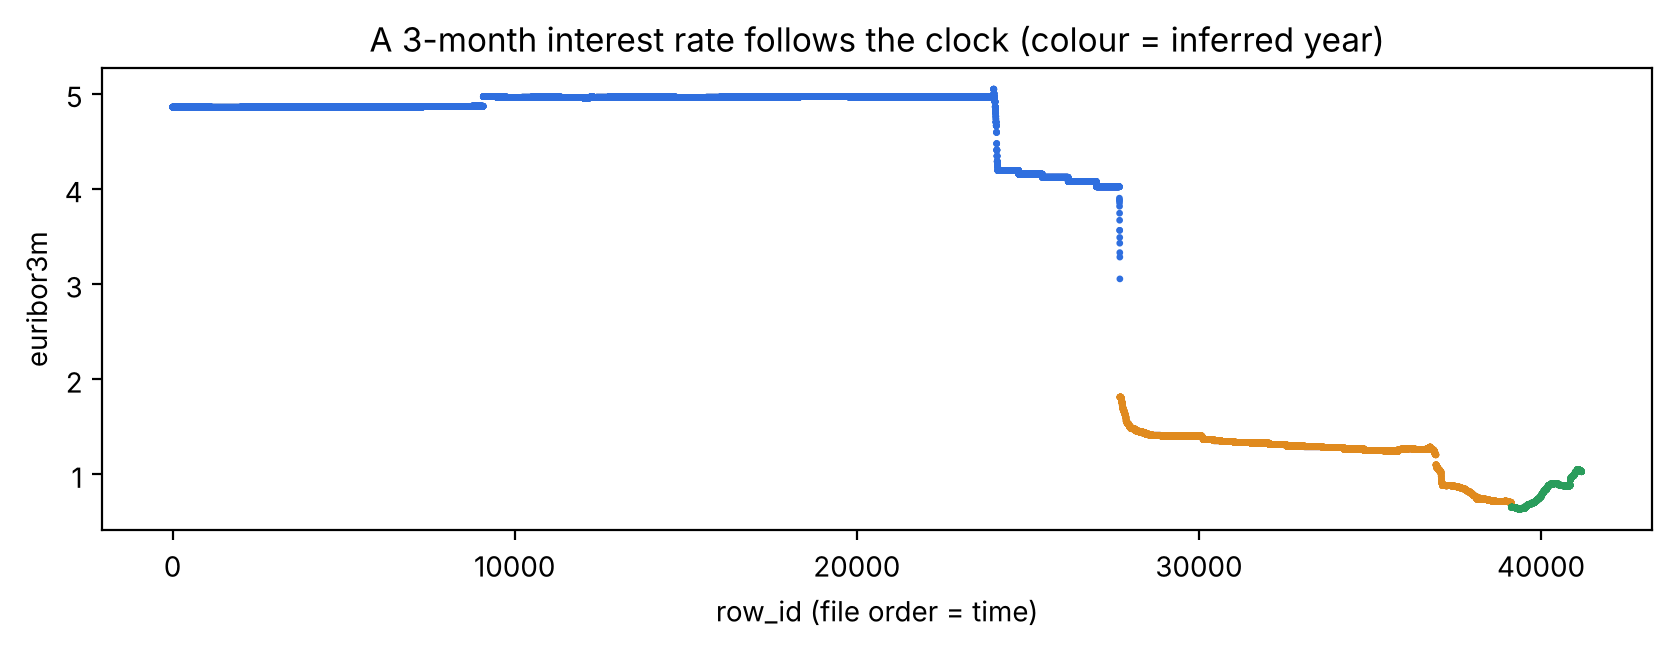

euribor3m       nr_employed        
                    min   max         min     max
inferred_year                                    
2008               3.05  5.04      5176.3  5228.1
2009               0.70  1.81      5017.5  5099.1
2010               0.63  1.05      4963.6  5008.7

In [11]:
# The economic columns against the clock (row order).
fig, ax = plt.subplots(figsize=(10, 3))
ax.scatter(df["row_id"], df["euribor3m"], s=2, c=df["inferred_year"].map(colors))
ax.set_xlabel("row_id (file order = time)")
ax.set_ylabel("euribor3m")
ax.set_title("A 3-month interest rate follows the clock (colour = inferred year)")
plt.show()

economy_by_year = df.groupby("inferred_year")[["euribor3m", "nr_employed"]].agg(["min", "max"]).round(2)
economy_by_year

**Conclusion.**
- **Real signals.** Earlier success is strong: 65.1% of clients whose earlier campaign succeeded said yes, against 8.8% where there was no earlier campaign. Students (31.4%) and retired clients (25.2%) say yes far more than blue-collar workers (6.9%). Calls on a mobile phone convert more than landline calls (14.7% against 5.2%), although that might partly reflect *when* each phone type was used (unverified).
- **Leakage demo: `duration`.** The yes-rate rises from 0.8% in the shortest quarter of calls to 29.2% in the longest. Long calls are mostly a *result* of the client being interested, not a cause that is known beforehand. This confirms the decision to exclude it.
- **`pdays`.** Clients with a real earlier contact say yes 63.8% of the time, against 9.3% for `pdays = 999`. A strong signal, as long as the 999 code is handled.
- **The economic columns follow the clock.** The 3-month interest rate falls in steps across the three inferred years: its range is 3.05 to 5.04 in 2008, 0.70 to 1.81 in 2009 and 0.63 to 1.05 in 2010. The ranges barely overlap. So a model trained on the early rows has *never seen* the values that appear in the test rows. This is observed in the data. **What it means for a model** is still a hypothesis: these columns may let it recognise the period instead of the client. We test it with an ablation.

## 7. Summary: what we found and what it means for the pipeline

| # | Finding | Consequence for the pipeline |
|---|---|---|
| 1 | Only 11.3% of calls end in a yes | Do not use accuracy. Use precision, recall, PR-AUC and precision among the top calls, each compared with its baseline |
| 2 | The row order follows the calendar, so it is a valid clock | Split chronologically (train, validation, test by row order), never randomly |
| 3 | The yes-rate rises from 4.8% (2008) to 19.5% (2009) to 52.1% (2010), inferred years | Compare each score with the baseline of the same set (about 0.056, 0.107 and 0.385). Expect the test period to differ from training |
| 4 | `unknown` hides missing values in six columns; `pdays = 999` is a code; 12 duplicates | Keep `unknown` as a category; turn `pdays = 999` into a flag; drop duplicates |
| 5 | `duration` is known only after the call and is strongly linked to the outcome | Exclude it. Show one labelled comparison *with* it to demonstrate leakage |
| 6 | `campaign`, `month`, `day_of_week` and the economic indicators have unclear timing; the economic ones follow the clock | Run ablations (with and without each group) and report the change in score |
| 7 | Earlier-campaign history, job, and contact type carry real signal | Keep them as features |

**Open questions for the bank:** does `campaign` include the call being predicted; what exactly do `month` and `day_of_week` record; why do some `pdays = 999` rows carry a recorded earlier "failure"; and why does the yes-rate rise so much over the three years?